# Model Evaluation Summary

This notebook dynamically loads the model comparison metrics (`comparison.json`) which reflects the latest pipeline performance on the IEEE-CIS Fraud Detection dataset, evaluated across four models: Logistic Regression, Isolation Forest, Random Forest, and XGBoost.

In [2]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. Load the comparison.json file
with open('../results/metrics/comparison.json') as f:
    eval_results = json.load(f)

# 2. Display a summary table of the evaluation
df_summary = pd.DataFrame([
    {
        'Model Name': model['name'],
        'Accuracy': model['accuracy'],
        'Precision': model['precision'],
        'Recall': model['recall'],
        'F1 Score': model['f1_score'],
        'AUC-ROC': model.get('auc_roc', 0.0)
    }
    for model in eval_results
])

df_summary.sort_values(by='F1 Score', ascending=False, inplace=True)
display(df_summary)

,Model Name,Accuracy,Precision,Recall,F1 Score,AUC-ROC
2,Random Forest,0.8795,0.111384,0.531250,0.184157,0.800515
0,Logistic Regression,0.8410,0.073529,0.449219,0.126374,0.676762
1,Isolation Forest,0.6529,0.042023,0.576172,0.078332,0.611987
3,XGBoost,0.9751,0.888889,0.031250,0.060377,0.790515


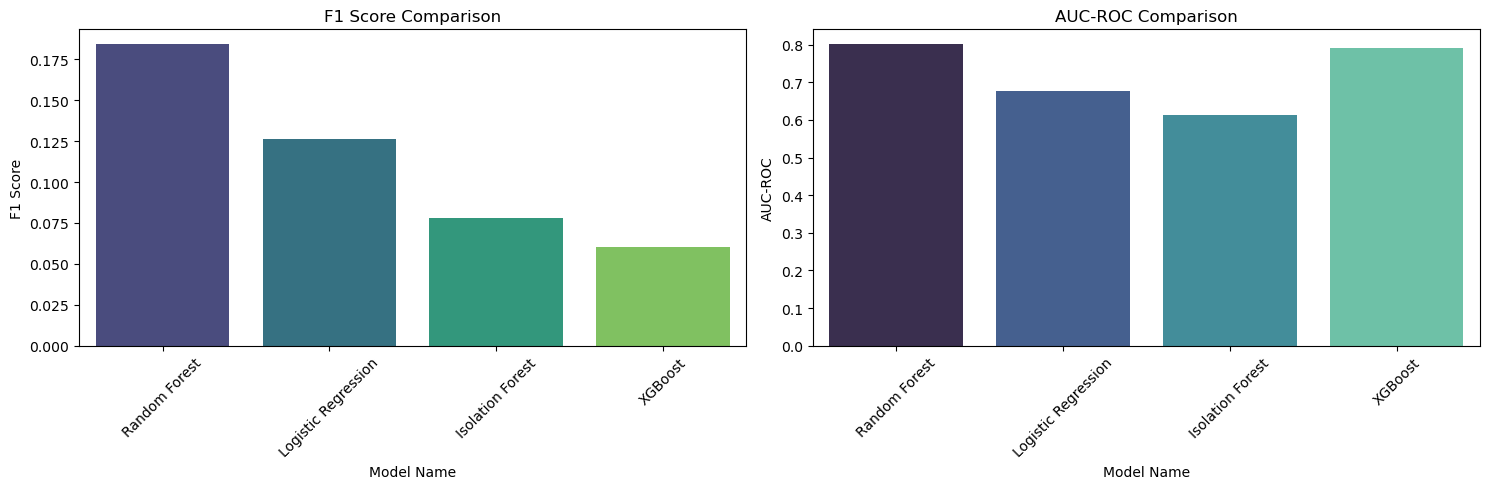

In [3]:
# 3. Plotting F1 Score and AUC-ROC
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(ax=axes[0], data=df_summary, x='Model Name', y='F1 Score', palette='viridis')
axes[0].set_title('F1 Score Comparison')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(ax=axes[1], data=df_summary, x='Model Name', y='AUC-ROC', palette='mako')
axes[1].set_title('AUC-ROC Comparison')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

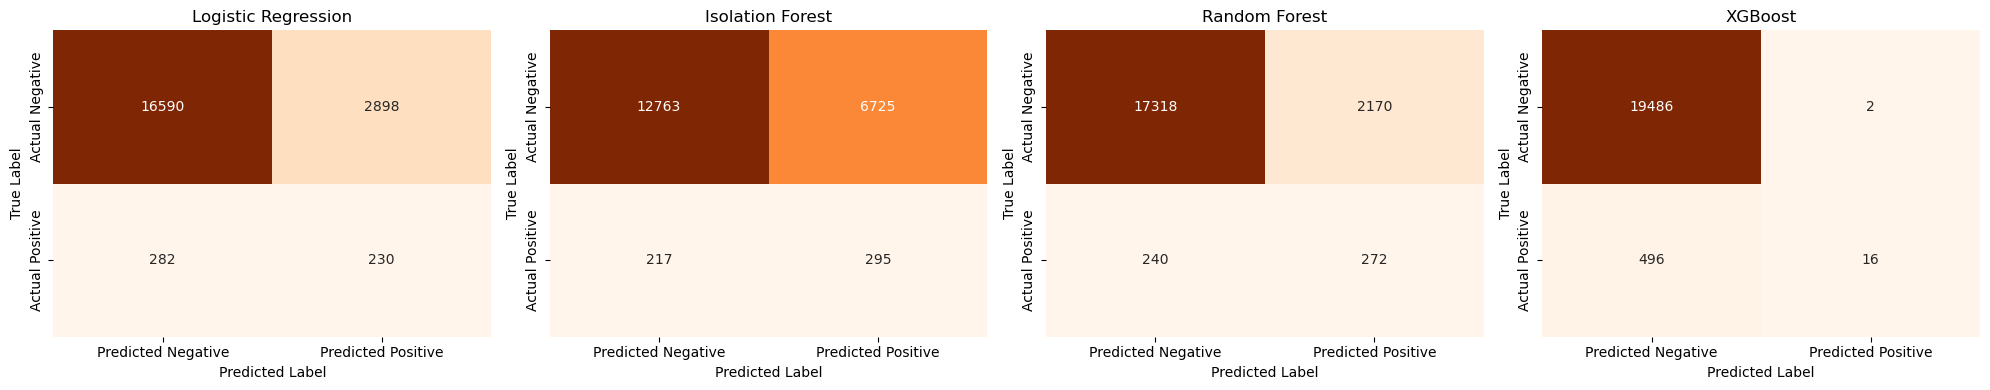

In [4]:
# 4. Plotting Confusion Matrices
fig, axes = plt.subplots(1, len(eval_results), figsize=(20, 4))
if len(eval_results) == 1:
    axes = [axes]

for i, model in enumerate(eval_results):
    cm = pd.DataFrame([
        [model['confusion_matrix']['true_negative'], model['confusion_matrix']['false_positive']],
        [model['confusion_matrix']['false_negative'], model['confusion_matrix']['true_positive']]
    ], index=['Actual Negative', 'Actual Positive'], columns=['Predicted Negative', 'Predicted Positive'])
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[i], cbar=False)
    axes[i].set_title(f"{model['name']}")
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.tight_layout()
plt.show()